# 07 积分系统：Bitmap 签到、事件发分与每日限额


## 本章范围与资料来源

第 05、06 章已经能回答问题并为内容点赞。本章把有效学习和互动行为转成积分，提供签到记录、今日积分统计和赛季列表，为第 08 章的排行榜准备数据。

| 来源 | 本章使用的内容 |
| --- | --- |
| [网盘分享](https://pan.baidu.com/s/1dcVvDI-sWN68Xzcsz1LSAQ?pwd=w7bj)，提取码 `w7bj` | `day07-积分系统/讲义/day07-积分系统.pptx`，共 29 页。接口、四类表、Bitmap、连续签到、积分上限、赛季列表 |
| [公开讲义转载：Day07-积分系统](https://imousse.github.io/cswiki/src/project/college/07-%E7%A7%AF%E5%88%86%E7%B3%BB%E7%BB%9F) | 积分规则、PointsRecordType、SignResultVO、签到与 MQ 代码、积分写入和今日统计。它是第三方转载，不能等同于已核验的官方最新源码 |
| 分享中的 `资料` 目录 | 确认含 `enums/PointsRecordType.java`、`query`、`vo`、`tj_points_board.sql`。枚举普通下载要求登录，未取得这些附件全文 |

阅读日期：2026-10-09。本章目录只显示 `讲义`、`资料`，未发现独立作业文件。练习范围采用已读转载讲义：查询签到记录、补齐学习和回答的积分事件、查询赛季列表、思考排行榜实现。

**课件方案**指 PPT 与转载讲义中明确出现的设计；**整理示例**是其关键代码的等价简化；**补充 / 改进示例**说明并发、消息与数据恢复边界。未取得的附件内容不作已读源码引用。

学习顺序：积分规则 → 表与接口 → Bitmap 签到 → 连续奖励 → MQ 发分 → 每日限额 → 今日统计 → 赛季与练习 → 一致性边界。

本 Notebook 全部使用 Markdown 单元。Java、Redis、SQL 等代码供阅读，不在 Python 内核执行；未连接课程服务或运行数据库脚本。


## 积分、签到进度与赛季

“我的积分”页面展示不同信息：今天从每类行为得到多少分、当月总积分与排名、签到日历。它们有不同的时间范围，不能用一个总数字代替。

| 信息 | 作用 | 时间范围 |
| --- | --- | --- |
| 签到状态 | 标记哪一天打卡，计算连续签到 | 当前自然月 |
| 积分明细 | 记录一次实际入账及来源类型 | 每次事件 |
| 今日积分统计 | 展示每类积分和每日上限 | 当前业务日 |
| 赛季总分与排行 | 比较学员本赛季积分 | 一个自然月 |
| 历史赛季 | 供查看已结束榜单 | 过去月份 |

课件规则是积分当月有效、月底清零，转载讲义明确**签到进度每月第一天重置**。因此 9 月末连续签到 5 天，10 月 1 日签到后，本月连续签到天数为 1。

“清零”表示新赛季从 0 开始，不等于必须删除过去所有积分明细。历史查询、纠错与对账是否保留原数据，需要配合归档策略；排行榜持久化在第 08 章展开。

积分可以激励学习，但本章没有定义可消费的钱包余额、兑换或扣款。不要把赛季成绩直接视为可支付余额。


## 积分获取规则与有效业务行为

规则决定谁能得分、每次得多少、每天最多多少。积分服务应接收业务成功后的事件，不能让用户直接提交任意分数。

| 方式 | 单次积分 | 每日上限 | 有效触发 |
| --- | --- | --- | --- |
| 签到 | 基础 1 分，里程碑额外奖励 | 无单独积分上限 | 今天首次签到 |
| 课程学习 | 10 分 | 50 分 | 一小节首次完成，视频或考试均可 |
| 课程问答 | 5 分 | 20 分 | 学员新增一级回答，不是提问或评论 |
| 写公开笔记 | 3 分 | 与笔记被采集合并上限 20 分 | 有效公开笔记提交 |
| 笔记被采集 | 2 分 | 同属笔记类型的 20 分上限 | 有效采集事件，归属作者 |
| 课程评价 | 10 分 | 无单独积分上限 | 已学习课程的有效评价，一课程一次 |

签到额外奖励：连续 7 天 +10、14 天 +20、28 天 +40。基础分与奖励分相加后入账。

> “无积分上限”仍受业务次数约束：签到一天一次、评价一课程一次。它不表示同一事件可以重复计分。

转载文字对笔记使用了“采集”和“点赞”两种表述，也有将评价简称为“评论”的段落。这里按规则表使用**笔记被采集**、**课程评价**，不自动把第 06 章任意点赞或问答评论都转换为积分。


## 接口总览与本章边界

页面查询采用 HTTP，业务成功后的发分通过 MQ。课件第 5 页共列出七项能力，后三项属于榜单，其中本章只实现赛季列表。

| 能力 | 方式与路径 | 请求 | 返回或处理 |
| --- | --- | --- | --- |
| 签到 | `POST /sign-records` | 无参数 | 连续天数和签到积分 |
| 查询本月签到 | `GET /sign-records` | 无参数 | 第 1 天到今天的 0/1 数组 |
| 新增积分记录 | MQ，按行为选择 routingKey | 通常 userId；签到另带 points | 消费后写积分明细 |
| 查询今日积分 | `GET /points/today` | 无参数 | 各类型已得积分与上限 |
| 查询本赛季榜单 | 第 08 章 | 本章不臆造路径 | 当月榜单与本人信息 |
| 查询赛季列表 | `GET /boards/seasons/list` | 无参数 | 本月及以前的赛季 |
| 查询历史榜单 | 第 08 章 | 本章不臆造路径 | 所选赛季的历史排名 |

表中是服务内路径，经网关访问的前缀以项目路由为准。签到与今日统计均从可信登录上下文取得当前用户；前端不需要传 userId 或日期。

PPT 签到响应概述为 `signDays`、`points`，转载代码拆分成 `signDays`、`signPoints`、`rewardPoints`。实现时核对真实 VO 与前端约定，不能同时把两种格式都当作现有接口。


## 积分明细表与数值范围

只保存当月总分无法回答“今天通过回答已得到多少分”。积分明细按每次实际入账保存用户、类型、分值和时间。

PPT 第 8 页的表结构整理，补齐通用表选项：

```sql
CREATE TABLE points_record (
    id BIGINT NOT NULL AUTO_INCREMENT COMMENT '积分记录id',
    user_id BIGINT NOT NULL COMMENT '用户id',
    type TINYINT NOT NULL COMMENT '1学习 2签到 3问答 4笔记 5评价',
    points TINYINT NOT NULL COMMENT '本次实际积分值',
    create_time DATETIME NOT NULL DEFAULT CURRENT_TIMESTAMP,
    PRIMARY KEY (id)
) ENGINE=InnoDB DEFAULT CHARSET=utf8mb4;
```

转载 DDL 还包含 `(user_id,type)` 和 `create_time` 索引，PPT 未列出。**补充索引选择**：日限额按用户、类型、时间查询，可评估 `(user_id,type,create_time)`；今日所有类型聚合可评估 `(user_id,create_time)`。索引增加写入成本，选择时用实际查询计划验证。

| 范围 | 类型与边界 |
| --- | --- |
| 一次入账 | 课程示例最大签到为 41，signed TINYINT 的 -128～127 可以存下 |
| 聚合总分 | 不应按 TINYINT 接收，SQL SUM 和 Java Long/Integer 按总范围选择 |
| 用户 ID | BIGINT，不能转换成 int |
| 将来大额奖励或扣回 | 评估把 points 改为 INT，并定义正负值规则 |

MySQL `TINYINT(3)` 中的 3 是旧显示宽度，不是“能存三位十进制整数”。当前表没有业务事件标识，后文会补充防重复发分的约束。


## 签到表与 Bitmap 的取舍

PPT 先设计每次签到一行的 `sign_record`，再说明大量用户多年累积的空间压力。第 12 页的 22 字节估算只统计了部分字段，不包含完整行、索引与存储管理开销。

课程关系表整理，移除 PPT 主键后的多余逗号以形成有效 SQL：

```sql
CREATE TABLE sign_record (
    id BIGINT NOT NULL AUTO_INCREMENT,
    user_id BIGINT NOT NULL,
    year YEAR NOT NULL,
    month TINYINT NOT NULL,
    date DATE NOT NULL,
    is_backup BIT(1) NOT NULL COMMENT '是否补签',
    PRIMARY KEY (id)
) ENGINE=InnoDB DEFAULT CHARSET=utf8mb4;
```

| 存储方案 | 优点 | 限制 |
| --- | --- | --- |
| 每天一行数据库记录 | 容易审计、记录补签与具体时间 | 记录数量大，需要索引和归档 |
| 用户每月一个 Bitmap | 最多 31 位表达当月是否签到，适合连续统计 | 单个位无法区分补签、正常签到和操作时间 |
| 数据库事实 + Bitmap 派生数据 | 可以重建位图并保留历史 | 要处理投影更新与一致性 |

本章课程实现选择 Redis Bitmap，签到账务明细仍写数据库。设计过 `sign_record` 不代表实际签到方法还会写这张表。

**补充**：若采用数据库方案，至少给 `(user_id,date)` 加唯一约束防重复。`is_backup` 只是模型预留，本章没有实现补签接口、资格校验或扣积分规则。


## 积分类型枚举与零上限语义

类型是数据库里的数字，而每日上限是类型的规则。转载讲义把两者集中在 PointsRecordType 中，便于消费者统一处理。

关键枚举内容，省略 Lombok 和 BaseEnum 的装配：

```java
LEARNING(1, "课程学习", 50),
SIGN(2, "每日签到", 0),
QA(3, "课程问答", 20),
NOTE(4, "课程笔记", 20),
COMMENT(5, "课程评价", 0);
```

| 属性或注解 | 含义 |
| --- | --- |
| `value` | 数据库存储的类型编号 |
| `desc` | 展示文字 |
| `maxPoints` | 每日积分上限，课程代码以 `>0` 判断是否限额 |
| `@EnumValue` | MyBatis-Plus 用该字段映射数据库值 |
| `@JsonValue` | JSON 用该字段序列化枚举 |
| `@JsonCreator` | 指定反序列化时的枚举转换入口 |

**0 在此表示“不设积分上限”，不是“禁止得分”。** 今日统计 VO 的 `type` 是描述字符串，与数据库编号或枚举 JSON 数值要区分。

转载 `of(value)` 对未知编号返回 null。补充建议：输入或数据库类型异常应有显式处理，不能在后续 `getDesc()` 才发生空指针。

规则也可放到 Nacos 动态读取，但需版本化和生效时间。修改上限不会自动重算历史明细，业务事件重放也应采用约定规则版本。


## 月度 Bitmap 与日期偏移

签到只需表达每天是否发生。Bitmap 将业务日期映射到二进制位：1 表示已签到，0 表示未签到。

课程按用户与月份隔离 key。整理示例：`sign:uid:7:202610` 保存用户 7 在 2026 年 10 月的签到。

| 日期 | Redis offset | 状态示例 |
| --- | --- | --- |
| 10 月 1 日 | 0 | 1 |
| 10 月 2 日 | 1 | 0 |
| 10 月 9 日 | 8 | 1 |

偏移公式：`offset = dayOfMonth - 1`。月份必须包含年份，否则 2026 年和 2027 年的十月会重用同一个 key。

```java
LocalDate today = LocalDate.now(clock);
String month = today.format(DateTimeFormatter.ofPattern("yyyyMM"));
String key = "sign:uid:" + currentUserId + ":" + month;
int offset = today.getDayOfMonth() - 1;
```

`clock` 是补充示例中的业务时钟，采用统一时区。本月最多 31 位的**位数据**需要至多 4 字节，Redis 还会保存 key、对象和分配开销，因此不能认为每用户每月总内存只有 4 字节。

Redis Bitmap 是 String 的按位操作，不是完全独立的底层类型。千万不要用雪花用户 ID 当 offset，极大偏移会迫使字符串分配大块空间。用户放在 key，日期才放在偏移里。


## SETBIT、GETBIT、BITFIELD 与 BITCOUNT

修改某一天、查询某一天、一次读取一段位以及统计 1 的数量，分别由不同命令完成。

```redis
SETBIT sign:uid:7:202610 0 1
SETBIT sign:uid:7:202610 1 1
SETBIT sign:uid:7:202610 2 1
SETBIT sign:uid:7:202610 5 1
SETBIT sign:uid:7:202610 6 1
SETBIT sign:uid:7:202610 7 1
BITFIELD sign:uid:7:202610 GET u8 0
```

最后得到从第 1 到第 8 天的 `11100111`，转无符号整数为 231。

| 命令 | 作用 | 本章用途 |
| --- | --- | --- |
| `SETBIT key offset 1` | 设置该位并返回修改前的位 | 首次签到判断 |
| `GETBIT key offset` | 返回某个位的 0/1 | 单日状态检查 |
| `BITFIELD key GET uN 0` | 从 0 开始读取 N 位，转为无符号整数 | 连续签到和月记录 |
| `BITCOUNT key` | 统计整个字符串中 1 的个数 | 月累计签到天数，不能直接表示连续天数 |

`u8` 中 u 表示无符号，8 是位宽。PPT 的 `u[dayOfMonth]` 是占位写法，例如今天第 9 天时实际发送 `u9`，不能把方括号直接传给 Redis。

缺失 key 的读位视为 0。连接超时是操作失败，不能当作缺失数据处理。


## 签到接口与原子防重复

用户连点或两个设备同时签到，必须保证只有一次有效打卡。先 GETBIT 再 SETBIT 会在两个命令之间产生竞争；课程直接依据 SETBIT 返回的旧值判断。

转载核心逻辑的整理示例：

```java
Long userId = UserContext.getUser();
LocalDate today = LocalDate.now(clock);
String key = signKey(userId, today);
int offset = today.getDayOfMonth() - 1;

Boolean old = redis.opsForValue().setBit(key, offset, true);
if (old == null) {
    throw new IllegalStateException("未取得签到结果");
}
if (old) {
    throw new BizIllegalException("不允许重复签到！");
}
int days = countSignDays(key, today.getDayOfMonth());
```

SETBIT 单命令原子执行。同一天两个请求只有第一个得到旧值 0，第二个得到 1。课程选择重复签到报业务错误；产品也可设计返回既有结果，但要保持“不再发分”。

> 位图写入的幂等性不等于整个签到加积分链路可靠。SETBIT 成功后发送 MQ 失败，重试会被“已签到”挡住，这个窗口在后文补充。

用户和日期由服务端决定。普通签到接口无日期参数，不允许用户直接给过去或未来日期打卡；补签需要独立业务规则。


## 连续签到的位运算

累计签到统计所有 1，连续签到只统计从今天往前、直到第一个 0 的那段。例：`11100111` 共签到 6 天，最近连续 3 天。

课程先读取第 1 天到今天的 N 位，今天对应整数的最低位。用 `value & 1` 取最低位，再用无符号右移 `>>>` 移除这一位。

```java
int countSignDays(String key, int days) {
    List<Long> values = redis.opsForValue().bitField(key,
        BitFieldSubCommands.create()
            .get(BitFieldSubCommands.BitFieldType.unsigned(days))
            .valueAt(0));
    if (values == null || values.size() != 1 || values.get(0) == null) {
        throw new IllegalStateException("未取得有效签到数据");
    }
    long bits = values.get(0);
    int count = 0;
    while (count < days && (bits & 1L) == 1L) {
        count++;
        bits >>>= 1;
    }
    return count;
}
```

| 过程 | 最低位 | 计数 |
| --- | --- | --- |
| `11100111` | 1 | 1 |
| `1110011` | 1 | 2 |
| `111001` | 1 | 3 |
| `11100` | 0 | 停止，结果 3 |

转载代码使用 int，本例使用 long 并限制循环位宽。一个月最多 31 位，两种都可处理；保留 Long 结果能减少扩展时的有符号转换误解。

这个算法在签到成功后执行，今天已被置 1。如果单独查询“截至今天连续签到”，今天没签时结果为 0；若产品要显示“截至昨天保持的连续”，应单独定义它的日期范围。


## 课件原图：连续签到统计

PPT 第 18 页展示从日期对应位图到整数、再逐位统计的算法。读取 N 位后，今天在最右端，往前走就是右移并继续查看最低位。

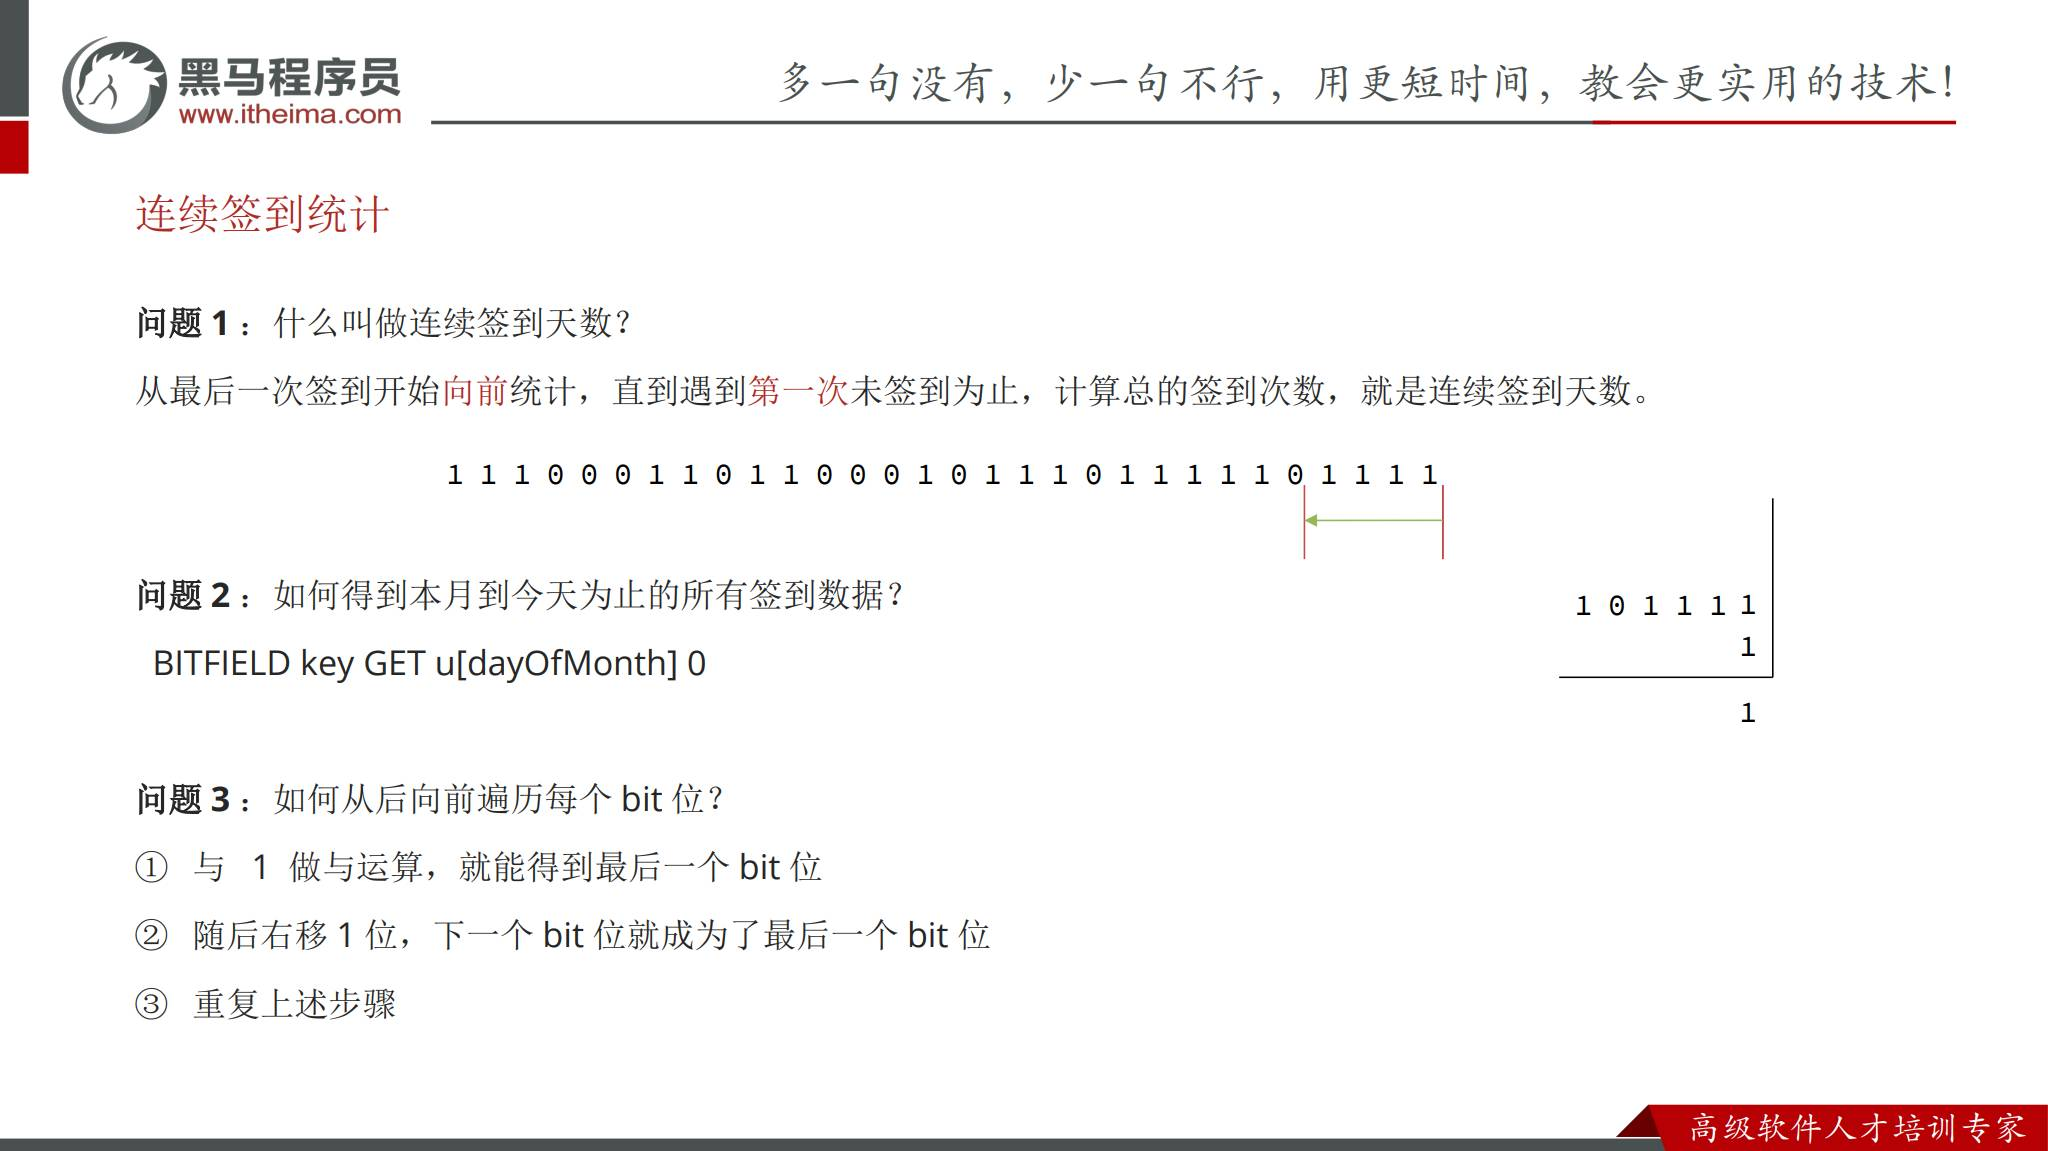

原图以当月数据解释连续天数。读取整个月的 31 位再直接统计最低位，会把未来尚未签到的 0 也放到右边，导致月中签到结果为 0。应读取“从第 1 天到今天”的位宽。


## 签到奖励与响应字段

额外奖励发在达到指定连续天数的当天，不是达到 7 天以后每天都奖励 10 分。

转载实现整理：

```java
int reward = switch (signDays) {
    case 7 -> 10;
    case 14 -> 20;
    case 28 -> 40;
    default -> 0;
};
int total = 1 + reward;
```

| 连续天数 | 基础分 | 额外分 | 当次入账 |
| --- | --- | --- | --- |
| 1～6 | 1 | 0 | 1 |
| 7 | 1 | 10 | 11 |
| 8～13 | 1 | 0 | 1 |
| 14 | 1 | 20 | 21 |
| 28 | 1 | 40 | 41 |
| 29～31 | 1 | 0 | 1 |

连续整月 31 天，共基础 31 分，加 10+20+40 的里程碑奖励，总计 101 分。这是按规则计算的例子，不是课程数据库现成记录。

转载 SignResultVO：`signDays`、`signPoints=1`、`rewardPoints`，并通过标记 `@JsonIgnore` 的 `totalPoints()` 供服务端求合计。建议明确把 rewardPoints 默认设为 0，避免未赋值时相加产生空指针。

课程先返回计算的得分、再由 MQ 异步写积分记录。响应里的得分含义是本次应发分值，不代表数据库明细已同步完成。


## 查询本月签到记录

页面日历需要每一天的状态，不能只拿连续天数或累计天数。`GET /sign-records` 返回第 1 天到今天的数组，长度就是今天在本月的日期数。

**练习整理示例**：读取 N 位后，从整数最低位往前拆，但写到数组末尾，保持日期从早到晚排列。

```java
List<Integer> queryMySignRecords() {
    LocalDate today = LocalDate.now(clock);
    int days = today.getDayOfMonth();
    long bits = readMonthBits(signKey(UserContext.getUser(), today), days);
    Integer[] records = new Integer[days];
    for (int i = days - 1; i >= 0; i--) {
        records[i] = (int) (bits & 1L);
        bits >>>= 1;
    }
    return Arrays.asList(records);
}
```

`readMonthBits` 使用前节的 BITFIELD 读取和结果校验。读取不存在的 key 会得到 0，此时数组仍保留 N 个 0。

例：第 4 天读取 `0111`，返回 `[0,1,1,1]`，不是 `[1,1,1,0]`。前导 0 不能因十进制表示而丢失，要靠明确的 days 位宽保留。

今天第 9 天就返回 9 项，未来日期由前端日历自行展示为不可签到。除非修改接口约定，不要擅自返回整月 31 项。


## 月切换、时区与 Bitmap 生命周期

日期决定键、偏移、积分归属。服务在不同默认时区运行，会在午夜前后把同一个操作记到不同日期。

**补充**：为业务选择统一时区，例如本项目用户按北京时间体验时使用 `Asia/Shanghai`，注入 Clock 并在请求入口取一次日期，后续计算复用它。

| 场景 | 本章语义 |
| --- | --- |
| 9 月 30 日到 10 月 1 日 | key 从 202609 换成 202610，新月从 0 开始 |
| 闰年二月 | 最后一天是 29，日期 API 计算，不硬编码 28 |
| 小月最后一天 | 只读当天位宽，不人为访问 31 日 |
| 请求跨过午夜 | 使用请求入口捕获的业务日期，按约定归属 |

这里**不拼上月 Bitmap**统计跨月连续，因为规则要求月初重置。如果另一产品明确要求跨月连续，那是新规则，需要读取前月末尾连续位并设计保留周期。

不要把当前月位图设置为很短的缓存 TTL，提前过期后同一天可能再次得到旧值 0。历史月可以在结算、归档、补偿窗口结束后按保留策略清理；这属于数据生命周期设计，不是本章实际执行操作。

补签、恢复位图或手动改位还可能重新命中奖励日，必须配合奖励事件唯一标识，不能只重跑 switch 重新发奖。


## MQ 事件发分与模块解耦

签到、学习、回答等业务都能产生积分。如果每个业务直接插入积分表，积分规则就分散在多个地方。课件使用 MQ，业务发布成功事件，积分消费者统一计算并保存。

```text
签到成功  ─ SignInMessage(userId, points) ─ 签到队列
回答成功  ─ userId                         ─ 回答队列
小节完成  ─ userId                         ─ 学习队列
                                  ↓
                     addPointsRecord(userId, points, type)
                                  ↓
                           points_record
```

转载示例使用 `MqConstants.Exchange.LEARNING_EXCHANGE`，各行为通过不同 routingKey 区分。类型由监听方法决定，固定分值由业务规则决定，所以多数消息只含 userId。

签到是例外：连续奖励不是固定值，消息体是 `SignInMessage(userId,points)`，points 为基础分加奖励分。它来自可信服务端计算，不是用户提交。

Spring 的应用事件可以在同服务内解耦，但普通 `@EventListener` 默认不等于异步，也不自动具有持久化重试能力。MQ 适合跨服务及将来的模块拆分，仍需设置队列、路由、消息确认与消费者重试。


## 签到消息与积分监听器

签到方法在 SETBIT、连续统计和奖励计算后发送 MQ。已读转载中的关键调用：

```java
mqHelper.send(
    MqConstants.Exchange.LEARNING_EXCHANGE,
    MqConstants.Key.SIGN_IN,
    SignInMessage.of(userId, rewardPoints + 1));
```

转载消息对象的核心字段：

```java
public class SignInMessage {
    private Long userId;
    private Integer points;
}
```

| 监听队列 | 绑定常量 | 消费参数与动作 |
| --- | --- | --- |
| `sign.points.queue` | `MqConstants.Key.SIGN_IN` | SignInMessage，按 SIGN 入账 |
| `qa.points.queue` | `MqConstants.Key.WRITE_REPLY` | userId，按 QA 发 5 分 |

监听核心整理：

```java
void listenSignInMessage(SignInMessage message) {
    recordService.addPointsRecord(
        message.getUserId(), message.getPoints(), PointsRecordType.SIGN);
}

void listenWriteReplyMessage(Long userId) {
    recordService.addPointsRecord(userId, 5, PointsRecordType.QA);
}
```

队列声明、Topic 交换机绑定和 `@RabbitListener` 在实际类中配置。常量的具体字符串应读取项目 `MqConstants`，本笔记不臆造未读到的 routingKey。

异步线程不能从 HTTP 的 UserContext 取得原用户，必须使用消息中的 userId。反过来，公开 HTTP 接口也不能任意接受消息字段来冒充用户。


## 学习与回答的积分事件触发

练习要求补齐学习、回答的生产者与监听器。事件触发点比“发消息的那行代码”更重要，否则高频学习进度上报会重复奖励。

| 行为 | 应发布的位置 | 不能作为触发的位置 |
| --- | --- | --- |
| 完成小节 | 从未完成变为已完成，且业务写入成功后 | 每次进度上报、每次打开视频 |
| 新增回答 | 学员首次新增一级回答成功后 | 提问、二级评论、编辑既有回答 |
| 完成考试小节 | 按完成规则首次变为完成后 | 每次重复提交同一考试 |

第 05 章的二层模型中，一级回答 `answer_id=0`，二级评论的 answer_id 指向根回答。这里的积分类型 COMMENT 是**课程评价**，不能用这个名字给二级问答评论发 10 分。

练习整理伪代码：

```java
if (becameFinished) {
    publishLearningCompleted(currentUserId);
}
if (createdRootAnswer && verifiedStudentRole) {
    publishAnswerCreated(currentUserId);
}
```

`becameFinished` 应由可靠的状态更新结果判断，而不是前端随意提交的完成标记。学员角色从服务端可信身份取得。

**补充**：数据库事务里直接发送消息，可能在回滚后仍发分。提交后事件改善回滚问题，但仍可能在提交与发送之间丢失消息，可靠投递可采用 Outbox，后文解释。


## 每日限额与实际入账

同一类型每次固定奖励，也可能在接近上限时只发剩余额度。例如笔记已得 19 分，再提交一篇应得 3 分，今天实际只能再得 1 分。

限额按 `(用户,积分类型,业务日)` 计算，不是用户所有类型共享一个上限。

| 上限 max | 当前已得 current | 应发 requested | 实发 |
| --- | --- | --- | --- |
| 20 | 0 | 5 | 5 |
| 20 | 18 | 5 | 2 |
| 20 | 20 | 5 | 0，不新增积分明细 |
| 0，代表不限额 | 任意 | 11 | 11 |

课件采用先查询今日该类型总分，再判断和保存。公式为：

```java
int actual = max > 0
    ? Math.min(requested, Math.max(0, max - current))
    : requested;
```

**数据库记录必须保存 actual，榜单累计也用 actual。** 若明细只发 1 分，榜单却累加 requested 的 3 分，两种数据会不同。

上限判断前还需校验 userId、type 与 requested。普通奖励事件必须大于 0；扣分纠错应走独立规则，不把负数奖励混入此方法。


## 资料图：积分入账流程

PPT 第 24 页和转载讲义采用相同分支：没有每日上限直接保存；有上限则查询今日已得积分并判断。这里内嵌已读转载中的清晰流程图。

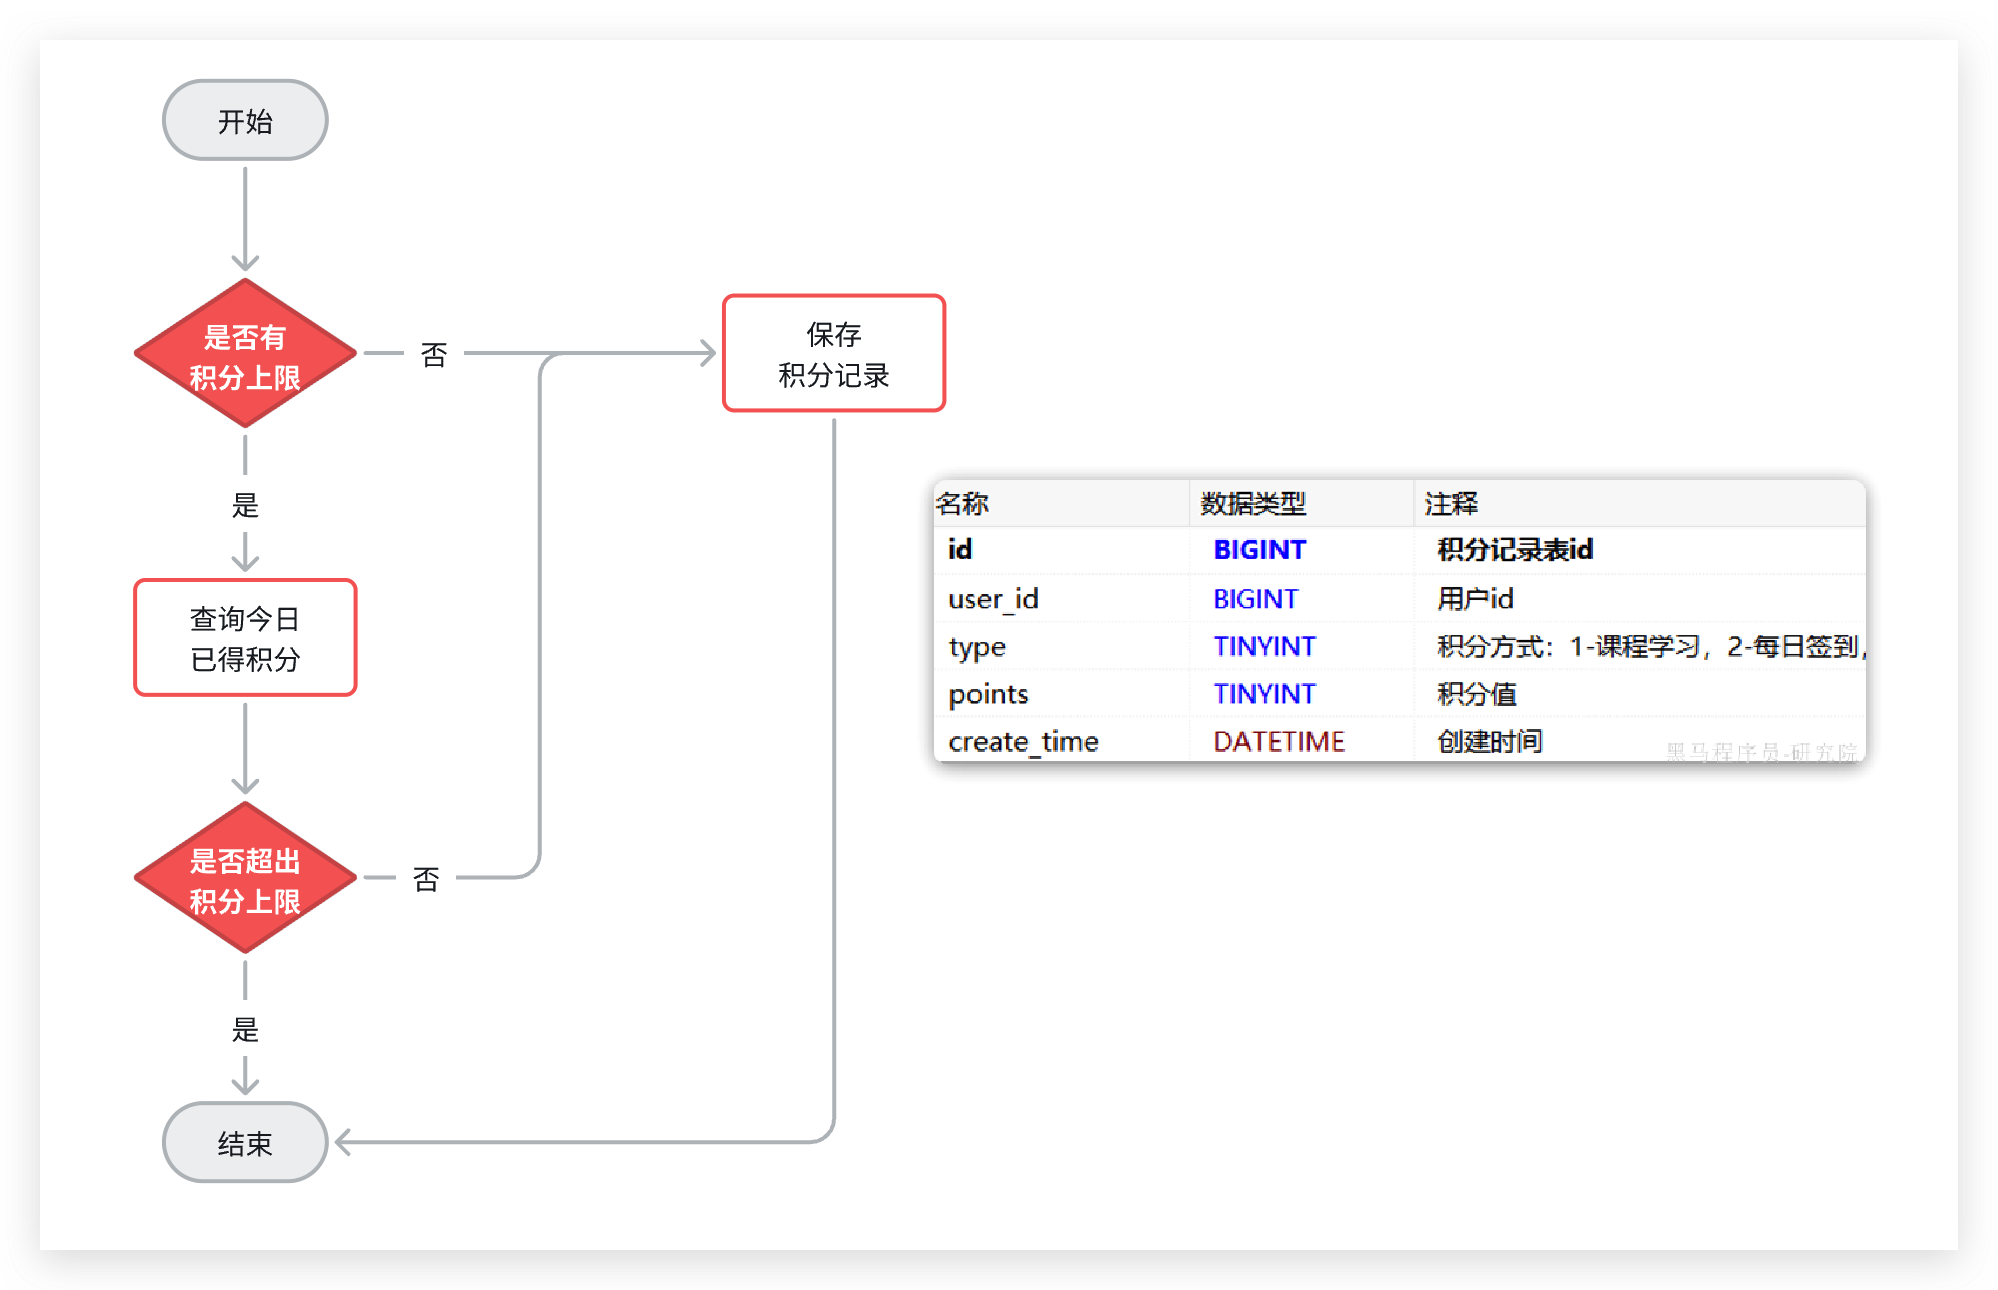

来源：[公开讲义“保存积分明细”](https://imousse.github.io/cswiki/src/project/college/07-%E7%A7%AF%E5%88%86%E7%B3%BB%E7%BB%9F#保存积分明细)。图省略了超限边缘时“只保存剩余额度”的细节，以后面的代码为准。

图是单次处理流程。多消费者同时查询同一份旧总数时，仍可能一起写入并超限，流程图本身没有并发互斥保证。


## 新增积分记录的课程实现

公共方法 `addPointsRecord(userId,points,type)` 接收已映射的类型，统一实现限额。下面保留转载中的核心控制流，时间查询改用清晰的辅助方法表示。

```java
void addPointsRecord(Long userId, int points, PointsRecordType type) {
    int max = type.getMaxPoints();
    int actual = points;
    if (max > 0) {
        int current = queryTodayPoints(userId, type);
        if (current >= max) {
            return;
        }
        actual = Math.min(points, max - current);
    }
    PointsRecord record = new PointsRecord();
    record.setUserId(userId);
    record.setType(type);
    record.setPoints(actual);
    save(record);
}
```

查询课程使用 SUM 并按用户、类型、日期筛选：

```sql
SELECT SUM(points)
FROM points_record
WHERE user_id = :userId
  AND type = :type
  AND create_time >= :begin
  AND create_time < :nextDay;
```

无匹配行时 SUM 返回 NULL，转换为 0。参数由框架绑定，不拼接用户输入。

转载用 DateUtils 的日开始、日结束配合 `between`，上面的 `[begin,nextDay)` 是补充的半开区间写法。课程方法没有业务事件去重，也没有并发锁；在多消费者场景需要后续改进。


## 聚合 Mapper 与查询条件安全

SUM 和 GROUP BY 不属于普通单表主键查询，课程定义自有 Mapper 方法，再通过 MyBatis-Plus Wrapper 拼装筛选条件。

转载核心声明：

```java
@Select("SELECT SUM(points) FROM points_record ${ew.customSqlSegment}")
Integer queryUserPointsByTypeAndDate(
    @Param(Constants.WRAPPER) QueryWrapper<PointsRecord> wrapper);

@Select("SELECT type, SUM(points) AS points " +
        "FROM points_record ${ew.customSqlSegment} GROUP BY type")
List<PointsRecord> queryUserPointsByDate(
    @Param(Constants.WRAPPER) QueryWrapper<PointsRecord> wrapper);
```

`${ew.customSqlSegment}` 插入的是由服务端 Wrapper 生成的 SQL 条件片段，用户值应由 Wrapper 的参数绑定传递。它**不允许**把前端任意 SQL 字符串、排序表达式或 `apply` 内容直接拼入查询。

| 方式 | 适用 |
| --- | --- |
| 标准 Wrapper + 固定 Mapper SQL | 课程的多条件聚合 |
| 显式参数 `#{userId}`、`#{begin}` | 条件固定时更直接，减少字符串 SQL 边界 |
| 专用聚合 DTO | 只承载 type、total，避免把聚合行误认作完整实体 |

转载复用 PointsRecord 承载 type 和聚合 points，其余字段为空。补充建议使用 `PointsTotal(type,total)`，并按可能的总分范围选择 Long。

不要用 `DATE(create_time)=...` 替代范围条件，函数包住索引列可能影响索引利用。可直接以 begin 和 nextDay 做范围筛选。


## 今日积分查询与按类型聚合

`GET /points/today` 展示当前用户今天每类已得积分及上限，一次 GROUP BY 可以得到全部类型，避免每种类型分别查库。

```sql
SELECT type, SUM(points) AS points
FROM points_record
WHERE user_id = :currentUserId
  AND create_time >= :begin
  AND create_time < :nextDay
GROUP BY type;
```

查询结果通过枚举补齐描述和上限：

```java
for (PointsTotal total : totals) {
    PointsRecordType type = PointsRecordType.of(total.type());
    if (type == null) {
        throw new IllegalStateException("不支持的积分类型");
    }
    result.add(new PointsStatisticsVO(
        type.getDesc(), type.getMaxPoints(), total.points()));
}
```

这是组装概念示例，实际 VO 构造器需按附件核对。响应中的 `type` 是描述，例如“课程学习”，`maxPoints=50`，`points=30`。

转载课堂代码只返回当天出现过记录的类型，无记录返回空集合。若页面要求固定显示五种来源，需在服务端按枚举补齐 0，或由前端使用类型配置补齐，明确一种契约即可。

签到和评价的 maxPoints=0 表示不限额，页面应按约定展示该含义，不能把 0 当成可用额度 0。MQ 尚未消费时，统计可能暂时落后于刚完成的操作。


## 每日限额的并发竞争

两个事件同时处理，同一用户问答今日已得 15 分。两次查询都看到 15，都认为还能发 5 分，最后总分变成 25，超过上限 20。

| 时刻 | 消费者 A | 消费者 B |
| --- | --- | --- |
| 1 | SUM 得到 15 | SUM 得到 15 |
| 2 | 计算实际 5 | 计算实际 5 |
| 3 | 保存 5 | 保存 5 |
| 最后 | 总分 25 | 上限失效 |

**补充**：给方法加事务只保证各自事务内的操作提交/回滚，不会自动把两个“先查再插”的事务串行化。普通 SUM 查询并不可靠地锁住“未来要插入的所有积分行”。

| 改进方式 | 关键条件 |
| --- | --- |
| 锁定用户、类型、日期的额度行 | 查询和更新同一额度，积分明细在同事务提交 |
| 按用户分片顺序消费 | 所有相关事件必须经过同一串行通道，包含重试与多实例 |
| 分布式锁 | 所有写入路径同一锁范围，考虑租约、事务和异常 |
| Redis 原子额度预占 | 要处理预占与数据库入账的失败补偿和去重 |

**实践场景**：业务主要在数据库入账时，额度行锁方便把限额、去重与明细放进一个事务；使用 Redis 提升高峰吞吐时，先设计预占事件的持久化和补偿，避免请求成功但数据库永久缺记录。


## 额度行与事务内入账改进

要可靠地限制每日类型总分，可以为 `(user_id,type,biz_date)` 保存一行已用额度，先锁这行，再计算 actual，最后更新额度和积分明细。

**补充 / 改进表结构**，课程材料未实现：

```sql
CREATE TABLE points_daily_total (
    user_id BIGINT NOT NULL,
    type TINYINT NOT NULL,
    biz_date DATE NOT NULL,
    total INT NOT NULL DEFAULT 0,
    PRIMARY KEY (user_id, type, biz_date)
) ENGINE=InnoDB;
```

事务流程示意：

```sql
BEGIN;
-- 先建立额度行；已存在时不改变 total
INSERT INTO points_daily_total(user_id,type,biz_date,total)
VALUES (:uid,:type,:date,0)
ON DUPLICATE KEY UPDATE total = total;

SELECT total FROM points_daily_total
WHERE user_id=:uid AND type=:type AND biz_date=:date
FOR UPDATE;

-- 应用在持有行锁期间按上限计算 actual
UPDATE points_daily_total SET total = total + :actual
WHERE user_id=:uid AND type=:type AND biz_date=:date;
-- actual > 0 时 INSERT 积分明细，事件收据也在本事务记录
COMMIT;
```

统一在事务内持有这行锁，避免读完额度就释放再另行写入。SQL 中的占位符是说明用法，不能原样当作数据库脚本执行。

上线到已有数据时，额度表先从明细正确初始化；所有发分写入路径必须接入这一机制，不能有另一入口绕过额度。事务也要包含下一节的事件唯一记录，防止重复投递。


## MQ 重复投递与发分幂等

积分是“加分”行为，与第 06 章设置总数快照不同。同一消息处理两次会新增两条明细；每日上限只能限制最终值，不能证明这次行为已经处理过。

课程大多数消息只含 userId，无法区分同一用户的两次真实回答和一次回答的重投。补充事件契约：

```json
{
  "eventId":"answer-created:201",
  "userId":7,
  "bizId":201,
  "eventType":"ANSWER_CREATED",
  "occurredAt":"2026-10-09T10:30:00+08:00"
}
```

| 行为 | 稳定的业务事件标识示例 |
| --- | --- |
| 签到 | 用户 + 业务日期 |
| 首次完成小节 | 用户 + 课程资格/课表 + 小节 + 约定完成周期 |
| 新增回答 | 回答 ID + 创建事件类型 |
| 笔记被采集 | 笔记 ID + 有效采集关系/操作 ID |
| 评价 | 评价 ID 或用户+课程的一次有效评价 |

eventId 在生产者重试时保持不变。消费时靠数据库唯一约束保存“这个事件已处理”，并把该记录同积分明细与额度更新放在一个事务。

**即使达到上限、actual=0，也要留下处理收据。** 否则今天拒绝的消息明天重试可能被当成新事件得分。收据可记录结果为 AWARDED 或 CAPPED，重复时返回既有结果。

不要只在 Redis SETNX 后直接入账：去重键成功、数据库失败会挡住重试。除非有可靠的状态和补偿机制，否则数据库事务中的唯一收据更便于保证一致。


## 业务日期、消息延迟与归属

转载课程代码在消费时取得当前时间，明细 create_time 也是写入时间。消息午夜前产生、午夜后消费时，它会进入后一日，月末延迟还会影响赛季。

| 时间 | 含义 |
| --- | --- |
| `occurredAt` | 业务行为实际成功时间 |
| `processedAt` / create_time | 消费者保存记录的时间 |
| `bizDate` | 按统一业务时区从事件时间或处理时间得到的归属日期 |
| `season` | 根据选定归属日期映射的赛季 |

**补充示例**：9 月 30 日 23:59 学完小节，10 月 1 日 00:01 才消费。如果按发生时间归属，应占用 9 月 30 日的学习额度，加入 9 月赛季；按处理时间则属于 10 月 1 日。必须选定规则，不能今日上限用一种日期、榜单用另一种。

可靠事件由可信服务端记录 occurredAt。业务日期、规则版本与去重结果固定下来后，重试时不重新套用当天日期。

如果允许旧赛季补记，还需规定结算窗口和榜单归档后的修正方式。过期事件应记录为明确的拒绝或补偿结果，不应不受控地给新月发分。

这是对课程“消费当前时间”实现的改进说明，原材料不包含这些新增字段和完整月末结算机制。


## 签到状态与积分事件的可靠衔接

SETBIT 成功之后、MQ 发送之前进程退出，用户会显示已签到，却没有积分事件。再次签到得到旧值 1，课程方法直接报重复，无法自动补上缺失消息。

| 故障窗口 | 结果 |
| --- | --- |
| 位图写入后、消息发送前退出 | 签到存在，积分通知缺失 |
| 消息发送成功但确认丢失 | 重试可能重复通知，需要事件去重 |
| 积分入账后、ACK 前退出 | MQ 再次投递，需要消费幂等 |

**补充 / 改进方案**：

1. 数据库作为签到事实来源，在同事务写唯一签到记录与 Outbox 事件。后台可靠发消息，Bitmap 成为可重建的查询投影。
2. 保留 Redis 作为签到来源，用 Lua 把设置位、计算结果与写待发送事件合在一次执行中，后台确认发送并恢复未完成事件。多键脚本在 Cluster 中需设计同槽键。

第二种方案还要配置 Redis 持久化与事件处理状态，Lua 原子执行不等于数据永不丢失。第一种方案增加数据库写入，但让签到事实、事件记录与纠错更容易对账。

Publisher Confirm 能确认 Broker 接收情况，但无法补回“发送前进程就退出”的事件。HTTP 成功响应、签到日历、积分明细是不同阶段，产品和实现应明确它们的状态关系。


## 消费事务、重试与无效业务纠错

积分消费者成功提交事务后再确认消息。数据库暂时失败时让异常传播，由配置的重试机制处理；不能捕获异常后假装成功。

| 情况 | 处理 |
| --- | --- |
| 同一事件重投 | 返回已有收据，不再加分 |
| 数据库连接失败 | 重试，保留事件身份和原日期 |
| 格式错误、非法 userId、未知类型 | 有限重试后进入隔离/死信队列并排查 |
| 上限已满 | 记录 CAPPED 收据，正常确认 |
| 业务记录后来判定无效 | 按规则撤销或补偿，保留审计信息 |

死信队列和重试次数要显式配置。无限重试无法修复不存在的类型，反而会堵塞处理。

规则称有效互动才能得分。若回答被认定灌水后删除，积分是否扣回、今日额度是否释放、历史赛季如何修正，都需要约定。本章没有实现自动撤销流程。

**补充**：纠错可记录与原事件关联的补偿明细，避免直接删除唯一发分证据后同一事件又能重放获奖。使用负分之前先评估表类型、聚合、榜单与额度的含义。


## 赛季表与榜单数据模型

赛季列表提供下拉选择，榜单数据表达该赛季的成绩。PPT 第 9 页分别设计 points_board_season 和 points_board。

课程赛季表整理：

```sql
CREATE TABLE points_board_season (
    id INT NOT NULL AUTO_INCREMENT,
    name VARCHAR(32) DEFAULT NULL,
    begin_time DATE NOT NULL,
    end_time DATE NOT NULL,
    PRIMARY KEY (id)
) ENGINE=InnoDB DEFAULT CHARSET=utf8mb4;
```

课程榜单表核心：

```sql
CREATE TABLE points_board (
    id BIGINT NOT NULL,
    user_id BIGINT NOT NULL,
    points INT NOT NULL,
    `rank` TINYINT NOT NULL,
    season SMALLINT NOT NULL,
    PRIMARY KEY (id)
) ENGINE=InnoDB DEFAULT CHARSET=utf8mb4;
```

转载表有唯一键 `(season,user_id)`，并说明 rank 只记录赛季前 100，PPT 未写这一范围。signed TINYINT 最大 127，若要存完整排行应改为足够范围的 INT。赛季主键 INT 与榜单引用 SMALLINT 也需统一或明确范围约束。

同一用户在不同赛季可以有不同成绩，不能只按 user_id 唯一。`rank` 是 SQL 关键字相关名称，用反引号保护或采用明确列名。

积分明细是入账事实，榜单是按赛季聚合后的数据。本章不实现实时排名、翻页、历史结算或分表，它们在第 08 章继续。


## 查询本月及以前的赛季

个人积分页切换历史榜单时，需要展示可选择的赛季。PPT 第 28 页要求返回**本月及之前**的全部赛季，不包括未来赛季。

| 字段 | 含义 |
| --- | --- |
| `id` | 赛季标识 |
| `name` | 赛季名称 |
| `beginTime` | 开始日期 |
| `endTime` | 结束日期 |

**练习整理 SQL**，按课程每月首日开赛的规则：

```sql
SELECT id, name, begin_time, end_time
FROM points_board_season
WHERE begin_time <= :firstDayOfCurrentMonth
ORDER BY begin_time DESC, id DESC;
```

新到旧便于用户选择近期赛季，PPT 未规定具体排序，本例选用这个顺序。如果表允许月中开赛，需要重新定义筛选为“截至今天已开始”或“本月所属赛季”，不能继续照搬月首条件。

本赛季已经开始但尚未结束，应当返回。筛选 `end_time < today` 只会返回已结束赛季，和课件要求不同。

数据库 DATE 常被产品定义为包含结束日；查询积分时可转为 `[beginTime零点, endTime+1日零点)`。赛季日期不应重叠，否则同一个业务日期无法唯一确定 season。


## 练习完成路线与排行榜衔接

本章练习集中在已有模型的接入，避免把统计接口和生产事件混在一起。

| 练习 | 完成判断 |
| --- | --- |
| 查询签到记录 | 返回从第 1 天到今天的完整 0/1 数组，顺序和长度正确 |
| 学习积分事件 | 小节首次完成后发通知，处理 10 分及学习日上限 50 |
| 回答积分事件 | 有效学员一级回答成功后发通知，处理 5 分及问答日上限 20 |
| 赛季列表 | 本月和历史赛季都返回，未来赛季不出现 |
| 思考榜单 | 区分明细、按赛季总分、实时排序和历史归档 |

课程尚未实现的公开笔记、采集、课程评价功能先保留规则，不凭空补建完整业务。增加真实模块时，再接入对应事件。

排行榜应累计**已经成功入账的实际积分**，而不是直接消费原始请求分数。同一个事件重放不能重复增加榜单分数，账务事实与排名投影需要一致的事件身份。

第 08 章会讨论用 ZSet 提供实时成绩排序，以及历史赛季持久化。本章的签到 Bitmap 和第 06 章的待同步 ZSet 都有各自语义，不能直接当作积分榜。


## Redis 数据恢复与历史保留

课程 Bitmap 保存签到，数据库保存积分，但两者不能相互完整替代。数据库积分记录没有明确签到日期、连续天数和事件身份时，很难恢复完全相同的位图与奖励结果。

| 数据 | 恢复依据 |
| --- | --- |
| 月度签到 Bitmap | Redis 持久化备份，或完整签到事实/事件日志 |
| 积分明细 | 数据库备份、事务记录与稳定事件收据 |
| 今日额度总表 | 从完整明细按业务日和类型重算 |
| 排行数据 | 从成功入账明细及赛季归属重建 |

**补充**：AOF、RDB、主从和哨兵提供不同层次的持久化与可用性，但不能因此保证所有已响应写入绝不丢失。选型要明确允许丢失多少数据、多久恢复，以及是否需要数据库作为事实来源。

积分“每月清零”的表注释不是数据库自动执行规则。新赛季从 0 计分、旧数据归档与删除是不同操作，不能仅凭注释定时清空整张明细表。

历史事件保留期应覆盖消费重试、补偿与结算修正期。过早删除去重收据，旧消息重放会再次获奖；只保留位图而删掉账务证据，也会让对账难以解释。


## 材料差异与实现核对项

| 项目 | 已读资料 | 实现时判断 |
| --- | --- | --- |
| 签到响应 | PPT signDays+points；转载 signDays+signPoints+rewardPoints | 按实际 VO 与前端统一 |
| 签到进度 | 转载明确月初重置 | 按月统计，不自行延长跨月连续 |
| 笔记奖励 | “采集”与“点赞”表述混用 | 确定有效采集业务，不默认所有点赞获奖 |
| 评论命名 | COMMENT 枚举描述为课程评价 | 不与问答二级评论混淆 |
| 签到 DDL | PPT 主键后有多余逗号 | 本笔记已去掉以便阅读有效 SQL |
| 积分索引 | 转载包含索引，PPT 没列 | 附件 SQL 未取得，实际迁移前核对 |
| 今日统计 | 转载只返回已得分类型 | 固定五项展示需要额外补零契约 |
| 时间边界 | 转载消费当前时间、between | 本笔记补充半开区间和事件日期 |
| 排名类型 | PPT TINYINT；转载说明只存前100 | 全量榜单需要扩大类型 |
| MQ 消息 | 通常仅 userId，签到另带积分 | 去重 eventId、业务日期是补充设计 |
| 额度锁、Outbox、事件收据 | 未出现在本章课程实现中 | 属于本笔记的改进说明 |

课程主线可以解释完整功能流程，但消息至少一次投递和多实例并发会放大边界问题。实现时把业务触发、限额、去重、投递与恢复分别核对。


## 业务验证场景

这些场景用于实现后验证。本笔记没有连接课程 Redis、MQ 或数据库执行它们。

| 场景 | 预期 |
| --- | --- |
| 第 1 天首次签到 | offset=0，连续1天，基础1分 |
| 同日连点、多设备并发 | 只有一次有效签到，不重复奖励 |
| `11100111` 的第8天 | 总签到6天，最近连续3天 |
| 第7、14、28天连续签到 | 当次分别入账11、21、41分 |
| 第8、15、29天连续签到 | 当次基础1分，不重复里程碑奖励 |
| 断签后重新签到 | 连续从1开始 |
| 月初、年初、闰日 | 月份键和位宽正确，新月重置 |
| 第4天状态 `0111` | 返回 `[0,1,1,1]`，保留前导0 |
| 今天无任何签到数据 | 返回长度为当日日期数的全0数组 |
| 学习重复进度上报 | 已完成小节不再次发分 |
| 二级回答评论或提问 | 不冒充一级回答积分事件 |
| 学习已50分再完成小节 | actual=0，不超学习日上限 |
| 笔记已19分，再应得3分 | actual=1，明细与后续榜单一致 |
| 两事件并发靠近上限 | 改进方案保证额度不超限 |
| 同一消息重复或次日重试 | 改进方案不再次获奖，日期不漂移 |
| 位图已写、MQ未发送时退出 | 可靠事件方案能恢复未发通知 |
| 当天尚无积分明细 | 按契约空列表或固定类型补零 |
| 查询赛季 | 返回本月及以前，排除未来 |
| Redis重启或事件重放 | 位图、积分、额度和去重证据可核对 |

验证性能时同时观察每日聚合查询、消费积压、最高入账延迟和重复事件比例。签到接口返回快，并不证明积分已经可靠入账。


## 面试提示与章节衔接

**面试提示**：签到用“用户+月份”的 Bitmap，日期映射为 dayOfMonth-1。SETBIT 返回旧位能原子判断首次签到；BITFIELD 读取本月到今天的位段，以 `&1` 和 `>>>1` 统计末尾连续1。积分明细按业务类型和业务日统计，超过上限只入剩余额度；有效业务通过 MQ 解耦发分。继续追问时能说明先查再插会并发超限、只有 userId 无法实现事件去重、SETBIT 与消息发送存在故障窗口，以及消费时间可能让月末事件归属错误。

| 易混点 | 正确区分 |
| --- | --- |
| 连续天数与累计天数 | 末尾连续1与全部1的数量不同 |
| Bitmap位数据与总内存 | 至多31位，不包含Redis键与对象开销 |
| 无积分上限与无限奖励 | 仍受业务次数、事件唯一性约束 |
| 事务与并发限额 | 事务提交不自动串行化SUM后写入 |
| 签到成功与积分入账 | 中间还有可靠投递与消费阶段 |
| 赛季清零与历史删除 | 新月从0开始仍可保留历史事实 |

到这里，签到事实与积分明细已经能解释“何时、因为什么得到多少分”。第 08 章进一步用这些实际入账数据形成实时榜单，并处理历史赛季查询与持久化。
